# Análise exploratória (EDA) – Fase 2

**Projeto:** Análise de Dados de Enchentes do INCT SiMAI
**Equipe:** Gustavo Fidelis, Leonardo Fagundes, Leonardo Mallet, Samuel Bitdinger

Este notebook usa os dados já limpos pelos scripts da pasta `scripts/`:

| Arquivo | Gerado por | Usado na |
|---|---|---|
| `dados/processados/inct_longo_limpo.csv` | `scripts/limpeza_inct.py` | Tela 1 |
| `dados/processados/inct_correcoes.csv` | `scripts/limpeza_inct.py` | registro das correções |
| `dados/processados/peers_longo.csv` | `scripts/limpeza_peers.py` | Tela 2 |
| `dados/processados/peers_taxas_renda.csv` | `scripts/limpeza_peers.py` | Tela 2 |

São 10 gráficos: 6 sobre a simulação do INCT (Tela 1) e 4 sobre a PEERS/IBGE (Tela 2).

> Todos os números são **estimativas**: a simulação do INCT supõe as pessoas distribuídas igualmente entre os prédios, e a PEERS é uma pesquisa amostral. Não são previsões nem contagens oficiais.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = RAIZ / "dados" / "processados"
FIG = RAIZ / "notebooks" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

AZUL, AZUL_CLARO, CINZA, LARANJA = "#1F4E79", "#9DC3E6", "#8C8C8C", "#C55A11"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
milhar = mtick.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))
RECORDE = 5.35

inct = pd.read_csv(PROC / "inct_longo_limpo.csv")
correcoes = pd.read_csv(PROC / "inct_correcoes.csv")
peers = pd.read_csv(PROC / "peers_longo.csv")
taxas = pd.read_csv(PROC / "peers_taxas_renda.csv")
print(inct.shape, correcoes.shape, peers.shape, taxas.shape)

(6674, 11) (75, 5) (1482, 13) (210, 8)


## Parte 1 – Simulação do INCT (Tela 1)

Conferência rápida do formato longo: 71 níveis × 94 bairros = 6.674 linhas, nenhum valor faltante.

In [2]:
print("níveis:", inct["nivel_m"].nunique(), "| bairros:", inct["bairro"].nunique())
print("faltantes:", int(inct.isna().drop(columns="correcao").sum().sum()))
print("população total:", f'{inct.query("nivel_m == 3.0")["population"].sum():,}'.replace(",", "."))
print("prédios no total:", f'{inct.query("nivel_m == 3.0")["total_buildings"].sum():,}'.replace(",", "."))
print("valores corrigidos por regra:")
print(correcoes["regra"].str[:2].value_counts().sort_index())

níveis: 71 | bairros: 94
faltantes: 0
população total: 1.332.845
prédios no total: 486.389
valores corrigidos por regra:
regra
3a     4
3b     1
3c     5
3d    65
Name: count, dtype: int64


### Gráfico 1 – População afetada em toda a cidade, por nível do rio

É o gráfico central da Tela 1. A linha cinza é o dado original, a azul é o dado limpo.

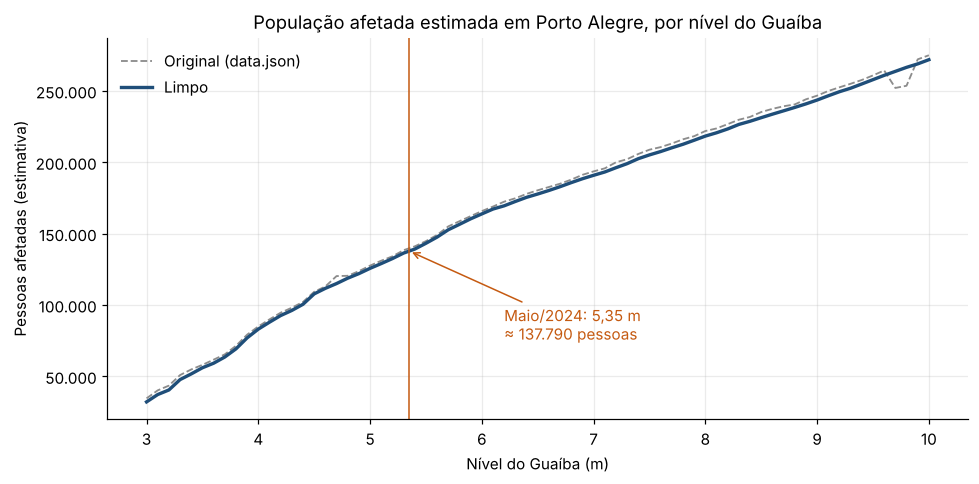

          limpo  original
nivel_m                  
3.0       32119     34605
5.3      136389    138414
5.4      139190    141108
10.0     271886    274993


In [3]:
cidade = inct.groupby("nivel_m").agg(limpo=("affected_population", "sum"),
                                     original=("affected_population_original", "sum"))
pop_recorde = np.interp(RECORDE, cidade.index, cidade["limpo"])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(cidade.index, cidade["original"], color=CINZA, lw=1.2, ls="--", label="Original (data.json)")
ax.plot(cidade.index, cidade["limpo"], color=AZUL, lw=2.2, label="Limpo")
ax.axvline(RECORDE, color=LARANJA, lw=1)
ax.annotate("Maio/2024: 5,35 m\n≈ " + f"{pop_recorde:,.0f}".replace(",", ".") + " pessoas",
            xy=(RECORDE, pop_recorde), xytext=(6.2, pop_recorde * 0.55),
            arrowprops=dict(arrowstyle="->", color=LARANJA), color=LARANJA)
ax.yaxis.set_major_formatter(milhar)
ax.set(xlabel="Nível do Guaíba (m)", ylabel="Pessoas afetadas (estimativa)",
       title="População afetada estimada em Porto Alegre, por nível do Guaíba")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "g01_populacao_por_nivel.png", dpi=150); plt.show()
print(cidade.loc[[3.0, 5.3, 5.4, 10.0]])

**Comentário.** A população afetada cresce de forma contínua: cerca de 32 mil pessoas a 3,0 m, cerca de 138 mil no nível recorde de maio de 2024 (5,35 m, interpolado entre 5,3 m e 5,4 m) e cerca de 272 mil a 10 m (20% da população da cidade). Na curva original aparecem dois "dentes" que não fazem sentido físico: um pico a 4,7 m (Espírito Santo) e uma queda a 9,7–9,8 m (Centro Histórico zerado). A curva limpa fica sempre um pouco abaixo da original porque o INCT arredondava duas vezes para cima (percentual e população); recalculamos sem esse arredondamento (detalhes no `relatorios/limpeza_dados.pdf`).

### Gráfico 2 – Antes e depois das correções nos bairros com inconsistências

Regra usada para encontrar os problemas: quando o rio sobe, o número de prédios afetados de um bairro **nunca pode diminuir**.

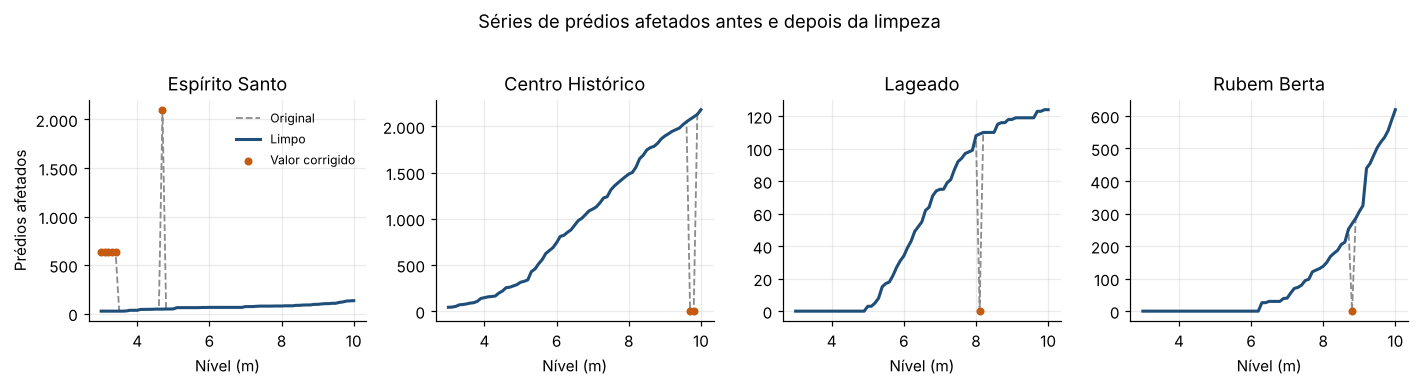

In [4]:
casos = ["Espírito Santo", "Centro Histórico", "Lageado", "Rubem Berta"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, b in zip(axes, casos):
    s = inct[inct["bairro"] == b].set_index("nivel_m")
    ax.plot(s.index, s["affected_buildings_original"], color=CINZA, lw=1.2, ls="--", label="Original")
    ax.plot(s.index, s["affected_buildings"], color=AZUL, lw=2, label="Limpo")
    fix = correcoes[correcoes["bairro"] == b]
    ax.scatter(fix["nivel_m"], fix["antes"], color=LARANJA, s=18, zorder=3, label="Valor corrigido")
    ax.set_title(b); ax.set_xlabel("Nível (m)"); ax.yaxis.set_major_formatter(milhar)
axes[0].set_ylabel("Prédios afetados"); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Séries de prédios afetados antes e depois da limpeza", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "g02_antes_depois.png", dpi=150, bbox_inches="tight"); plt.show()

**Comentário.** As quatro inconsistências maiores ficam evidentes no gráfico:
- **Espírito Santo:** 637 prédios afetados de 3,0 m a 3,4 m, mas só 25 a 3,5 m e 133 a 10 m. Isso é impossível, então trocamos pelo primeiro valor válido (25). Também há um pico isolado de 2.101 prédios a 4,7 m, entre 46 e 47, que foi interpolado.
- **Centro Histórico (9,7 m e 9,8 m), Lageado (8,1 m) e Rubem Berta (8,8 m):** o valor cai para zero no meio de uma série crescente, provavelmente uma falha da simulação ou da exportação. Foi interpolado entre os vizinhos.

Além desses, o **Arquipélago** oscila entre 4.674 e 4.688 prédios afetados (quase 100% do bairro desde 3,0 m). Aplicamos o máximo acumulado, uma diferença de no máximo 14 prédios.

### Gráfico 3 – Quantos bairros são atingidos em cada nível

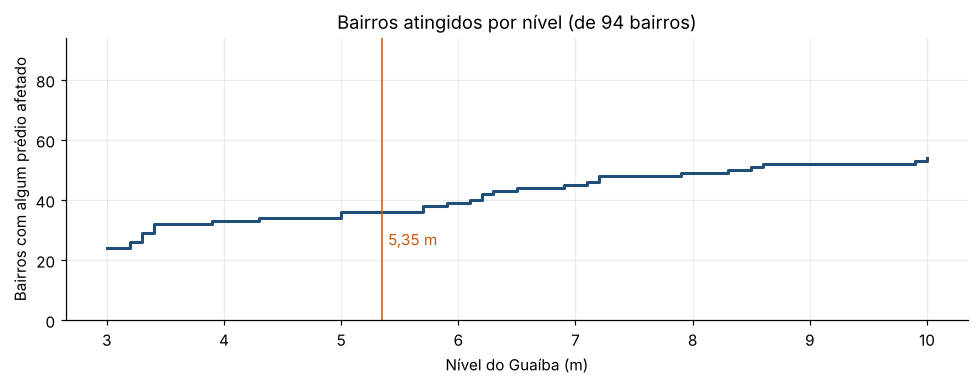

{3.0: 24, 5.3: 36, 10.0: 54} | nunca atingidos: 40


In [5]:
atingidos = inct[inct["affected_buildings"] > 0].groupby("nivel_m")["bairro"].nunique()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.step(atingidos.index, atingidos.values, where="post", color=AZUL, lw=2)
ax.axvline(RECORDE, color=LARANJA, lw=1); ax.text(RECORDE + 0.05, 25, "5,35 m", color=LARANJA)
ax.set(xlabel="Nível do Guaíba (m)", ylabel="Bairros com algum prédio afetado", ylim=(0, 94),
       title="Bairros atingidos por nível (de 94 bairros)")
fig.tight_layout(); fig.savefig(FIG / "g03_bairros_atingidos.png", dpi=150); plt.show()
print(atingidos.loc[[3.0, 5.3, 10.0]].to_dict(), "| nunca atingidos:", 94 - inct.loc[inct.affected_buildings > 0, "bairro"].nunique())

**Comentário.** Já a 3,0 m, 24 bairros têm algum prédio atingido. No nível de 2024 são 36 e a 10 m, 54. **40 bairros nunca são atingidos** na simulação, o que faz sentido porque ficam nas partes altas da cidade. Esse é o indicador "bairros atingidos" do topo da Tela 1.

### Gráfico 4 – Ranking dos bairros mais afetados no nível de 2024 (5,3 m)

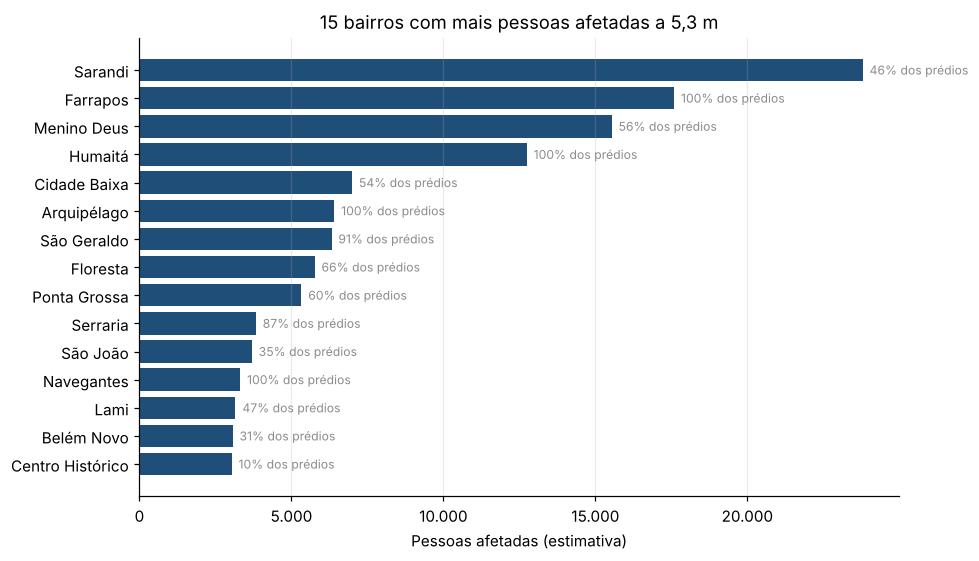

In [6]:
n53 = inct[inct["nivel_m"] == 5.3].sort_values("affected_population", ascending=True).tail(15)
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(n53["bairro"], n53["affected_population"], color=AZUL)
for y, (p, pct) in enumerate(zip(n53["affected_population"], n53["percentage"])):
    ax.text(p, y, f"  {pct:.0f}% dos prédios", va="center", fontsize=8, color=CINZA)
ax.xaxis.set_major_formatter(milhar)
ax.set(xlabel="Pessoas afetadas (estimativa)", title="15 bairros com mais pessoas afetadas a 5,3 m")
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG / "g04_ranking_53m.png", dpi=150); plt.show()

**Comentário.** O ranking muda conforme a métrica. Em **pessoas**, lideram Sarandi (cerca de 23,8 mil), Farrapos (17,6 mil) e Menino Deus (15,5 mil). Em **percentual de prédios**, seis bairros chegam a 100% (Arquipélago, Anchieta, Farrapos, Praia de Belas, Navegantes, Humaitá). Por isso a Tela 1 mostra as duas coisas: o gráfico de % por bairro (requisito) e o ranking por pessoas.

### Gráfico 5 – Mapa de calor: % de prédios afetados por bairro e nível

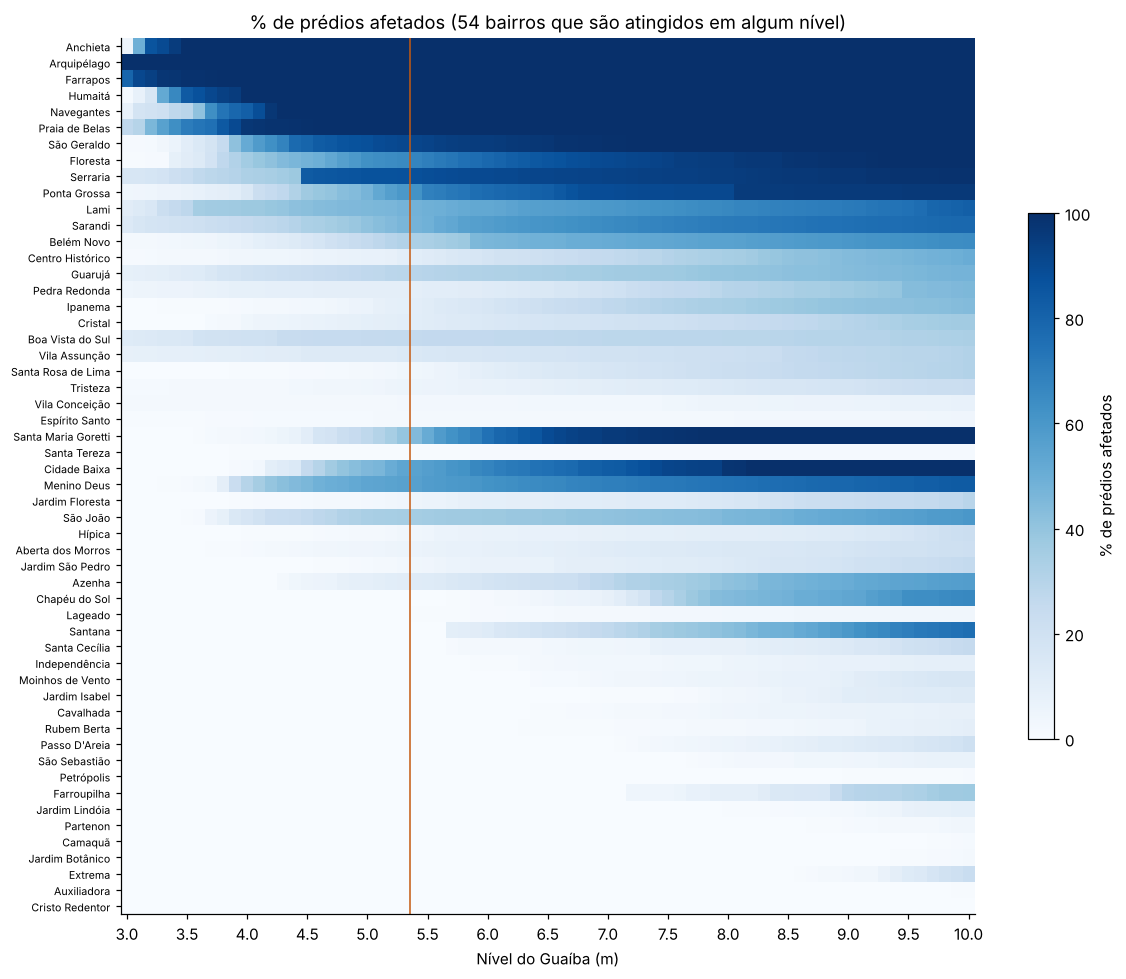

In [7]:
pivo = inct.pivot(index="bairro", columns="nivel_m", values="percentage")
pivo = pivo[pivo.max(axis=1) > 0]
ordem = pd.DataFrame({"inicio": (pivo > 0).idxmax(axis=1), "pct10": -pivo[10.0]}).sort_values(["inicio", "pct10"])
pivo = pivo.loc[ordem.index]
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(pivo.values, aspect="auto", cmap="Blues", vmin=0, vmax=100)
ax.set_yticks(range(len(pivo))); ax.set_yticklabels(pivo.index, fontsize=7)
xt = [i for i, n in enumerate(pivo.columns) if abs(n * 2 - round(n * 2)) < 1e-9]
ax.set_xticks(xt); ax.set_xticklabels([f"{pivo.columns[i]:.1f}" for i in xt])
ax.axvline(list(pivo.columns).index(5.3) + 0.5, color=LARANJA, lw=1)
ax.set(xlabel="Nível do Guaíba (m)", title="% de prédios afetados (54 bairros que são atingidos em algum nível)")
ax.grid(False); fig.colorbar(im, ax=ax, label="% de prédios afetados", shrink=0.6)
fig.tight_layout(); fig.savefig(FIG / "g05_mapa_calor.png", dpi=150); plt.show()

**Comentário.** Os bairros estão ordenados pelo nível em que começam a ser atingidos. Há dois comportamentos. Bairros da orla norte e ilhas (Arquipélago, Farrapos, Humaitá, Navegantes) já estão quase totalmente alagados a 3–4 m. Bairros mais altos (Rubem Berta, Lageado, Hípica) só entram acima de 8 m e com percentuais baixos. O gráfico também serviu de checagem visual: depois da limpeza nenhuma linha "clareia" quando o nível sobe.

### Gráfico 6 – Pessoas por prédio em cada bairro (limitação da estimativa)

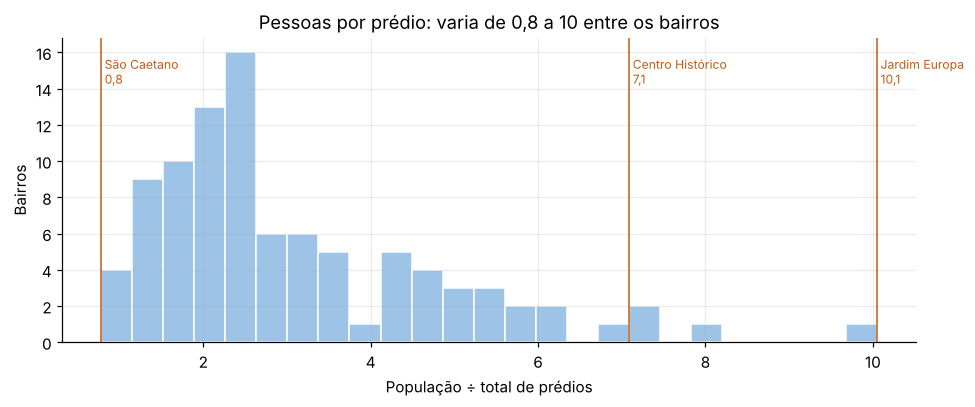

count    94.00
mean      3.09
std       1.75
min       0.78
25%       1.98
50%       2.42
75%       4.11
max      10.05
Name: pessoas_por_predio, dtype: float64


In [8]:
base = inct[inct["nivel_m"] == 3.0].assign(pessoas_por_predio=lambda d: d["population"] / d["total_buildings"])
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(base["pessoas_por_predio"], bins=25, color=AZUL_CLARO, edgecolor="white")
for b in ["Jardim Europa", "Centro Histórico", "São Caetano"]:
    v = base.loc[base["bairro"] == b, "pessoas_por_predio"].iloc[0]
    ax.axvline(v, color=LARANJA, lw=1); ax.text(v, ax.get_ylim()[1] * 0.85, f" {b}\n {v:.1f}".replace(".", ","), fontsize=8, color=LARANJA)
ax.set(xlabel="População ÷ total de prédios", ylabel="Bairros",
       title="Pessoas por prédio: varia de 0,8 a 10 entre os bairros")
fig.tight_layout(); fig.savefig(FIG / "g06_pessoas_por_predio.png", dpi=150); plt.show()
print(base["pessoas_por_predio"].describe().round(2))

**Comentário.** A população afetada do INCT é `população × prédios afetados ÷ total de prédios`, ou seja, supõe as pessoas espalhadas igualmente por **todos** os prédios, inclusive os não residenciais. A razão varia muito: cerca de 7 pessoas por prédio no Centro Histórico (prédios altos) e menos de 1 em São Caetano. Em bairros com muitos galpões ou comércio na área baixa, a estimativa tende a errar. Isso entra no **aviso de limitações** da Tela 1.

## Parte 2 – PEERS/IBGE (Tela 2)

As 21 tabelas foram convertidas para um formato longo (`peers_longo.csv`), com o coeficiente de variação (CV) de cada estimativa. Com o CV calculamos o intervalo de confiança de 95%: `valor ± 1,96 × CV × valor`.

In [9]:
print(peers.groupby("tabela").size().rename("linhas").to_frame().T)
print("estimativas com CV acima de 15% (menos precisas):", int(peers["cv_alto"].sum()))

tabela  1   2   3   4    5   6    7    8    9   10  ...  12  13  14  15  16  \
linhas  46  64  14  60  112  34  176  176  112  48  ...  48  12  48  48  10   

tabela   17  18  19  20   21  
linhas  100  80  48  48  186  

[1 rows x 21 columns]
estimativas com CV acima de 15% (menos precisas): 54


### Gráfico 7 – O que aconteceu nos domicílios e nos bairros (Tabela 6)

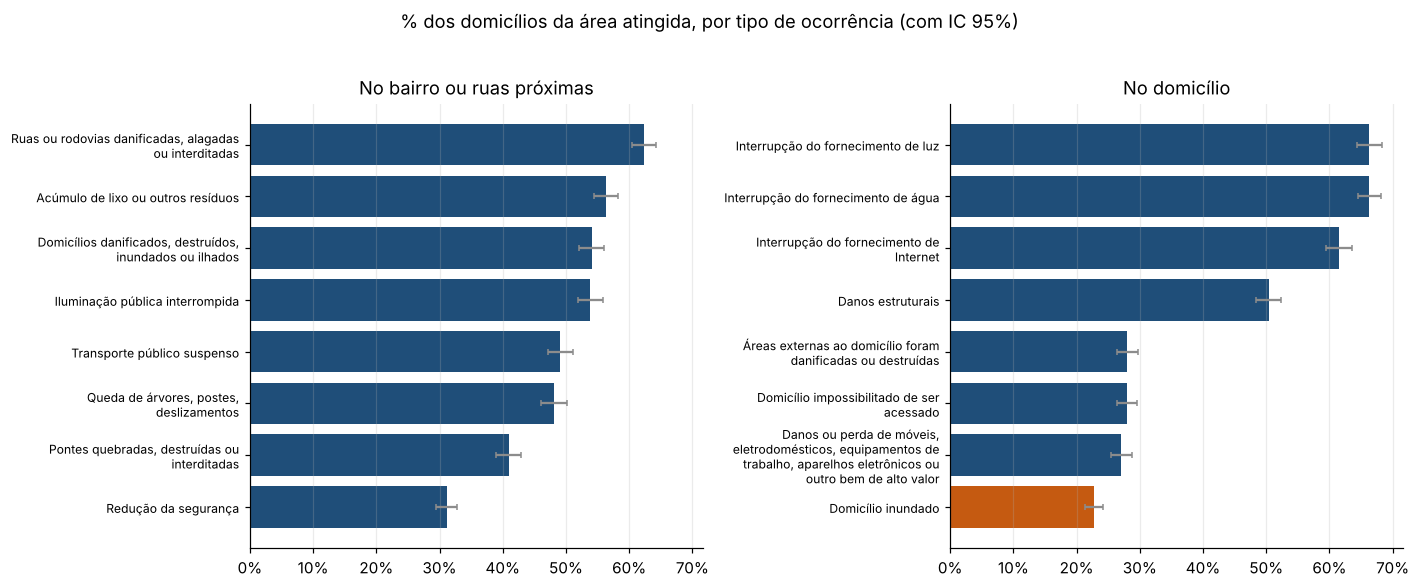

In [10]:
t6 = peers[(peers["tabela"] == 6) & (peers["medida"] == "percentual") & (peers["grupo"] != "Total")].copy()
import textwrap
t6["rotulo"] = (t6["categoria"].str.replace(r"\s*\(.*\)", "", regex=True).str.rstrip(" .,")
                .map(lambda t: textwrap.fill(t, 38)))
t6["erro"] = 1.96 * t6["cv_pct"] / 100 * t6["valor"]
t6 = t6.sort_values(["grupo", "valor"])
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharex=True)
for ax, (g, sub) in zip(axes, t6.groupby("grupo", sort=False)):
    cores = [LARANJA if r == "Domicílio inundado" else AZUL for r in sub["rotulo"]]
    ax.barh(sub["rotulo"], sub["valor"], xerr=sub["erro"], color=cores, ecolor=CINZA, capsize=2)
    ax.set_title("No domicílio" if "domicílio" in g else "No bairro ou ruas próximas")
    ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("% dos domicílios da área atingida, por tipo de ocorrência (com IC 95%)", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "g07_ocorrencias.png", dpi=150, bbox_inches="tight"); plt.show()

**Comentário.** Só **22,8%** dos domicílios foram inundados (em laranja, o que a simulação do INCT tenta estimar), mas **66%** ficaram sem água e sem luz, 50% tiveram danos estruturais e 28% ficaram inacessíveis. No bairro, 62% relatam ruas alagadas ou interditadas. Esta é a principal ligação com a Tela 1: a mancha d'água mostra só uma parte do impacto. Os intervalos de confiança são estreitos (CV de 1% a 3%), então as diferenças entre categorias são confiáveis. A pergunta tem múltipla resposta, por isso os percentuais não somam 100% e não usamos pizza.

### Gráfico 8 – A renda muda o impacto? Taxas por classe de renda

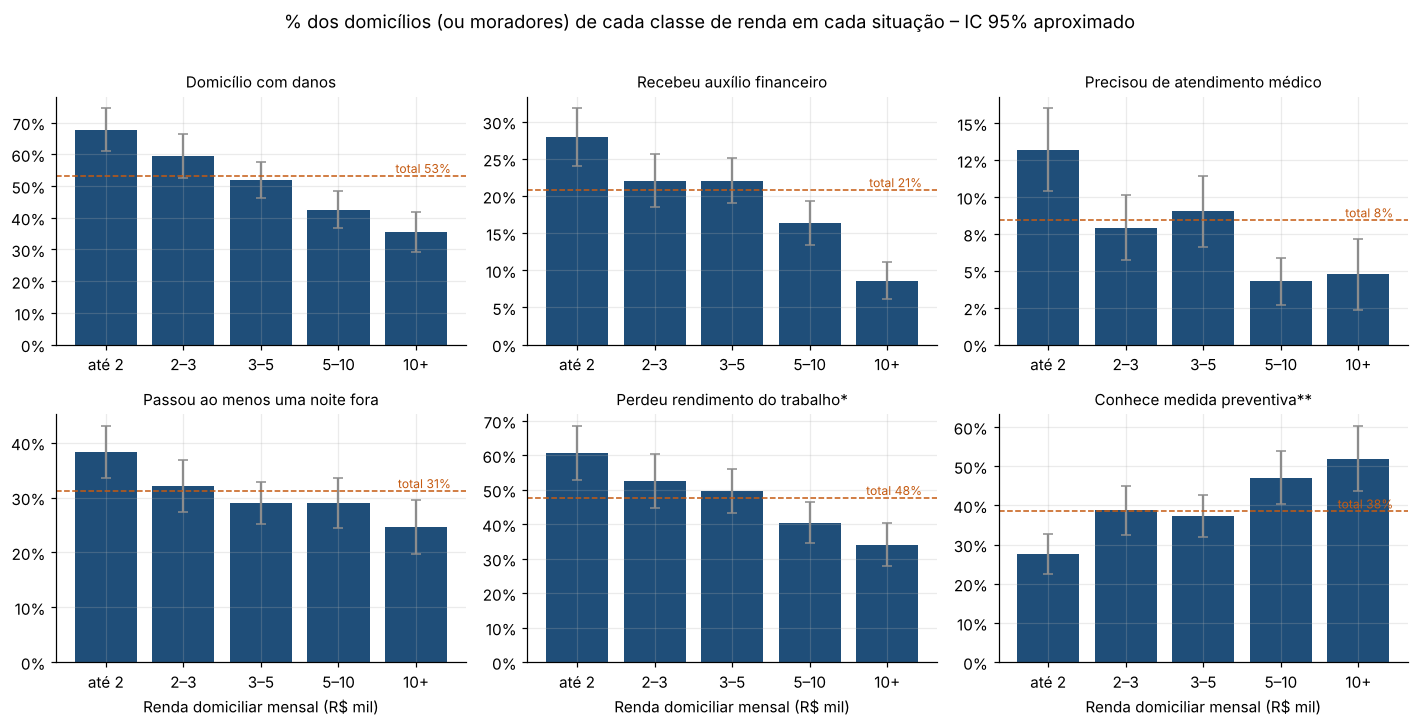

                        indicador  até R$ 2 mil  mais de R$ 10 mil  total
0             Domicílio com danos          67.8               35.5   53.2
1      Recebeu auxílio financeiro          27.9                8.6   20.8
2  Precisou de atendimento médico          13.2                4.8    8.4
3  Passou ao menos uma noite fora          38.4               24.7   31.2
4  Perdeu rendimento do trabalho*          60.8               34.1   47.7
5     Conhece medida preventiva**          27.6               52.0   38.5


In [11]:
indicadores = [
    (4,  "condição estrutural do domicílio depois das enchentes | Com danos", "Domicílio com danos"),
    (5,  "recebeu auxílio financeiro público | Sim", "Recebeu auxílio financeiro"),
    (5,  "Necessidade de atendimento médico de algum morador do domicílio devido às enchentes | Sim", "Precisou de atendimento médico"),
    (10, "passar ao menos uma noite fora devido às enchentes | Sim", "Passou ao menos uma noite fora"),
    (17, "Existência de perda do rendimento do trabalho | Sim", "Perdeu rendimento do trabalho*"),
    (19, "amenizar os impactos de futuras enchentes | Sim", "Conhece medida preventiva**"),
]
classes = ["Até R$ 2 mil", "R$ 2 a 3 mil", "R$ 3 a 5 mil", "R$ 5 a 10 mil", "Mais de R$ 10 mil"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharey=False)
resumo = []
for ax, (tab, trecho, nome) in zip(axes.flat, indicadores):
    sub = taxas[(taxas["tabela"] == tab) & taxas["coluna"].str.contains(trecho, regex=False)].set_index("classe")
    v = sub.loc[classes, "taxa_pct"]; total = sub.loc["Total", "taxa_pct"]
    erro = 1.96 * sub.loc[classes, "cv_pct"] / 100 * v
    ax.bar(range(5), v, yerr=erro, color=AZUL, ecolor=CINZA, capsize=3)
    ax.axhline(total, color=LARANJA, lw=1, ls="--"); ax.text(4.45, total, f"total {total:.0f}%", color=LARANJA, fontsize=8, va="bottom", ha="right")
    ax.set_xticks(range(5)); ax.set_xticklabels(["até 2", "2–3", "3–5", "5–10", "10+"])
    ax.set_title(nome, fontsize=10); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    resumo.append((nome, v.iloc[0], v.iloc[-1], total))
for ax in axes[1]: ax.set_xlabel("Renda domiciliar mensal (R$ mil)")
fig.suptitle("% dos domicílios (ou moradores) de cada classe de renda em cada situação – IC 95% aproximado", y=1.01)
fig.tight_layout(); fig.savefig(FIG / "g08_taxas_renda.png", dpi=150, bbox_inches="tight"); plt.show()
print(pd.DataFrame(resumo, columns=["indicador", "até R$ 2 mil", "mais de R$ 10 mil", "total"]).round(1))

**Comentário.** Este é o gráfico que responde à pergunta da Tela 2. Em quase todos os indicadores há um **gradiente por renda**:
- domicílios com danos: 68% na classe mais baixa contra 35% na mais alta;
- auxílio financeiro público: 28% contra 9%;
- atendimento médico: 13% contra 5%;
- noite fora de casa: 38% contra 25%;
- perda de rendimento do trabalho: 61% contra 34%.

O único indicador que inverte é o conhecimento de medidas preventivas, maior entre os mais ricos (52% contra 28%). Isso sugere que quem mais sofreu é quem menos sabe o que está sendo feito.

\* universo: moradores de 14 anos ou mais que trabalhavam. \*\* universo: moradores.
O intervalo é aproximado (usa só o CV do numerador). Na Fase 3 este gráfico vira o filtro "indicador" da Tela 2.

### Gráfico 9 – Para onde foram os que precisaram sair de casa (Tabela 11)

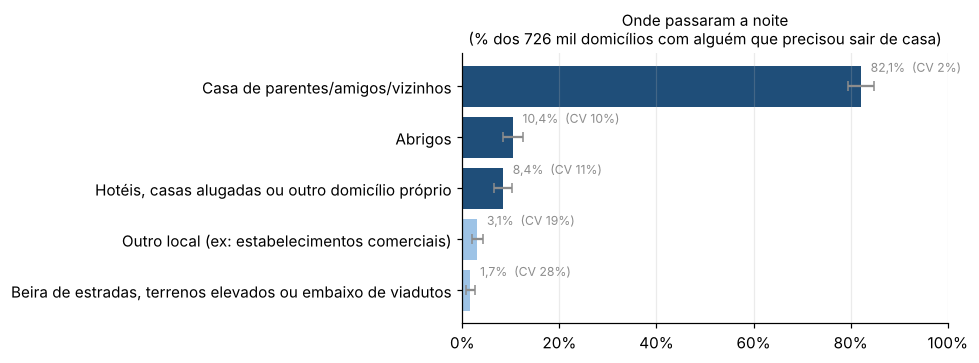

In [12]:
t11 = peers[(peers["tabela"] == 11) & (peers["medida"] == "percentual") & (peers["categoria"] != "Total")].copy()
t11["erro"] = 1.96 * t11["cv_pct"] / 100 * t11["valor"]
t11 = t11.sort_values("valor")
fig, ax = plt.subplots(figsize=(9, 3.4))
cores = [AZUL_CLARO if alto else AZUL for alto in t11["cv_alto"]]
ax.barh(t11["categoria"], t11["valor"], xerr=t11["erro"], color=cores, ecolor=CINZA, capsize=3)
for y, (v, cv) in enumerate(zip(t11["valor"], t11["cv_pct"])):
    ax.text(v + 2, y + 0.28, f"{v:.1f}%  (CV {cv:.0f}%)".replace(".", ","), fontsize=8, color=CINZA)
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 100)
ax.set_title("Onde passaram a noite\n(% dos 726 mil domicílios com alguém que precisou sair de casa)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "g09_onde_passaram_noite.png", dpi=150); plt.show()

**Comentário.** A rede de apoio foi principalmente informal: **82%** foram para a casa de parentes, amigos ou vizinhos e **10%** para abrigos. As barras claras têm CV acima de 15% (por exemplo, "beira de estradas", com CV de 29%). No dashboard elas aparecem com aviso de baixa precisão, como recomenda o IBGE.

### Gráfico 10 – Ligação entre as telas: o evento de 2024 visto pelas duas bases

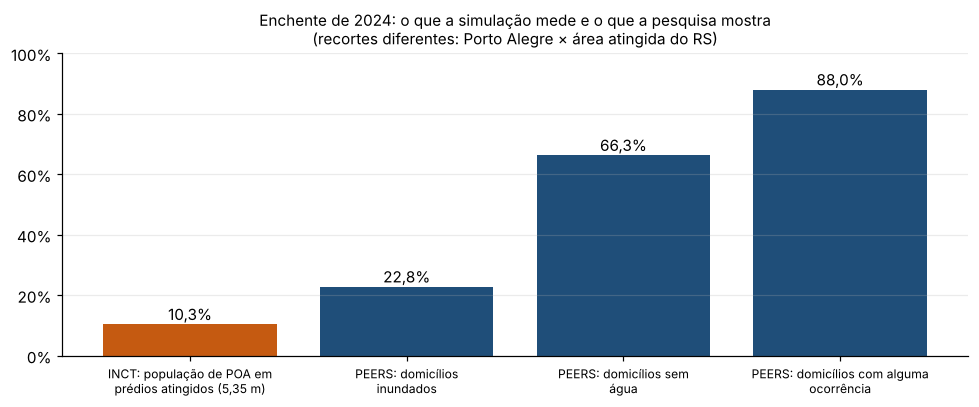

INCT: população de POA em\nprédios atingidos (5,35 m)    10.3
PEERS: domicílios\ninundados                             22.8
PEERS: domicílios sem\nágua                              66.3
PEERS: domicílios com alguma\nocorrência                 88.0
dtype: float64


In [13]:
pop_poa = inct.query("nivel_m == 3.0")["population"].sum()
inct_pct = pop_recorde / pop_poa * 100
t6p = peers[(peers["tabela"] == 6) & (peers["medida"] == "percentual")].set_index("categoria")["valor"]
t1 = peers[(peers["tabela"] == 1) & (peers["medida"] == "percentual")]
alguma = t1[(t1["grupo"].str.contains("ocorrências causadas")) & (t1["categoria"] == "Sim")]["valor"].iloc[0]
barras = pd.Series({
    "INCT: população de POA em\nprédios atingidos (5,35 m)": inct_pct,
    "PEERS: domicílios\ninundados": t6p["Domicílio inundado"],
    "PEERS: domicílios sem\nágua": t6p["Interrupção do fornecimento de água"],
    "PEERS: domicílios com alguma\nocorrência": alguma,
})
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(barras.index, barras.values, color=[LARANJA, AZUL, AZUL, AZUL])
for x, v in enumerate(barras.values):
    ax.text(x, v + 1.5, f"{v:.1f}%".replace(".", ","), ha="center")
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_ylim(0, 100); ax.grid(axis="x", visible=False)
ax.set_title("Enchente de 2024: o que a simulação mede e o que a pesquisa mostra\n(recortes diferentes: Porto Alegre × área atingida do RS)", fontsize=10)
ax.tick_params(axis="x", labelsize=8)
fig.tight_layout(); fig.savefig(FIG / "g10_ligacao_telas.png", dpi=150); plt.show()
print(barras.round(1))

**Comentário.** No nível de 2024, a simulação estima cerca de **10%** da população de Porto Alegre em prédios atingidos pela água. Na área atingida do RS, a PEERS registra **23%** dos domicílios inundados e **88%** com alguma ocorrência. Os recortes são diferentes (município × 133 municípios) e os métodos também (simulação × pesquisa), então os números **não devem ser comparados como iguais**. A leitura correta é de ordem de grandeza: o impacto vivido foi muito mais amplo do que a área alagada. Esta é a visualização que liga a Tela 2 à Tela 1 (requisito 3), e na Tela 2 ela terá esse aviso escrito.

## Resumo para as próximas fases
- **Tela 1:** gráficos 1, 3 e 4 viram os indicadores, a curva e o ranking. O gráfico 6 vira o aviso de limitações.
- **Tela 2:** gráficos 7 a 10, com filtro de indicador (gráfico 8) e de domicílio/bairro (gráfico 7).